# T1-3: Solid Body Rotation (3D)

## Verification Study — Tier 1 / Trivial Trajectories

**Field:** $u = -\Omega\,y$, $v = \Omega\,x$, $w = W_0$ (constant vertical velocity)

**Analytical trajectory:**
$$x(t) = R\cos(\Omega t + \varphi_0), \quad y(t) = R\sin(\Omega t + \varphi_0), \quad z(t) = z_0 + W_0 t$$
where $R = \sqrt{x_0^2 + y_0^2}$ and $\varphi_0 = \mathrm{atan2}(y_0, x_0)$.

**Purpose:** Extends T1-2 to 3D grid; checks 3D interpolation stencils. With $W_0 \neq 0$ the
trajectory is a helix; with $W_0 = 0$ it reduces to the 2D circle (sanity check).

**Expected convergence:** Order $p$ (integrator order) in $\Delta t$ for node-centered grids
(exact interpolation of the linear horizontal field plus constant vertical).

---

### Approach

We construct a Delaunay triangulation over a square domain centered at the origin with
multiple vertical layers. The velocity field is:

- **Horizontal:** solid-body rotation $u = -\Omega y$, $v = \Omega x$ (linear, same as T1-2)
- **Vertical:** constant $w = W_0$ (uniform)

Two data configurations:
- **Face-centered (U, V) + node-centered (W):** horizontal velocity on face centers,
  vertical velocity on nodes with layer interfaces
- **Node-centered (U, V, W):** all velocity components on nodes

We sweep all interpolator / time integrator combinations and verify against the analytical
helix. We also run a $\Delta t$ convergence study on the node-centered configuration.

In [1]:
import math
import os
import shutil

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32 (~1e-6 deg resolution);
# use float64 positions so the error tolerances below are meaningful.
Particle64 = get_default_particle(np.float64)

## 1. Parameters

In [2]:
# Domain (centered at origin so rotation center = (0, 0))
NX = 40  # Grid points per side
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

# Vertical domain — multiple layers
NZ_LAYERS = 10  # number of layers
Z_MIN, Z_MAX = 0.0, 100.0  # depth range
zf = np.linspace(Z_MIN, Z_MAX, NZ_LAYERS + 1, dtype=np.float64)  # layer interfaces
zc = 0.5 * (zf[:-1] + zf[1:])  # layer centers

# Rotation rate
OMEGA = 2.0 * np.pi / 3600.0  # one full revolution in 3600 s
PERIOD = 2.0 * np.pi / OMEGA  # 3600 s

# Vertical velocity
W0 = 0.005  # degrees/s (constant upward)

# Time — run for 1 full orbit
N_ORBITS = 1
T_TOTAL_S = N_ORBITS * PERIOD
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_BASE = np.timedelta64(30, "s")

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particle initial positions — ring at various radii, mid-depth
RADII = [1.0, 2.0, 3.0]
ANGLES_PER_RING = 4
Z0 = 50.0  # starting depth (middle of domain)

p_lon0, p_lat0 = [], []
for R in RADII:
    for k in range(ANGLES_PER_RING):
        theta = 2.0 * np.pi * k / ANGLES_PER_RING
        p_lon0.append(R * np.cos(theta))
        p_lat0.append(R * np.sin(theta))
p_lon0 = np.array(p_lon0, dtype=np.float64)
p_lat0 = np.array(p_lat0, dtype=np.float64)
p_depth0 = np.full_like(p_lon0, Z0)
N_PARTICLES = len(p_lon0)

print(f"\u03a9 = {OMEGA:.6e} rad/s, period = {PERIOD:.1f} s")
print(f"W0 = {W0} degrees/s")
print(f"Vertical domain: {Z_MIN} to {Z_MAX}, {NZ_LAYERS} layers")
print(f"Total runtime = {T_TOTAL_S:.0f} s  ({N_ORBITS} orbits)")
print(f"{N_PARTICLES} particles at radii {RADII}, z0 = {Z0}")

Ω = 1.745329e-03 rad/s, period = 3600.0 s
W0 = 0.005 degrees/s
Vertical domain: 0.0 to 100.0, 10 layers
Total runtime = 3600 s  (1 orbits)
12 particles at radii [1.0, 2.0, 3.0], z0 = 50.0


## 2. Build Unstructured Grid

In [3]:
lon, lat = np.meshgrid(
    np.linspace(LON_MIN, LON_MAX, NX, dtype=np.float64),
    np.linspace(LAT_MIN, LAT_MAX, NX, dtype=np.float64),
)
lon_flat = lon.ravel()
lat_flat = lat.ravel()

# Boundary mask for Delaunay
mask = (
    np.isclose(lon_flat, LON_MIN)
    | np.isclose(lon_flat, LON_MAX)
    | np.isclose(lat_flat, LAT_MIN)
    | np.isclose(lat_flat, LAT_MAX)
)
boundary_points = np.flatnonzero(mask)

uxgrid = ux.Grid.from_points(
    (lon_flat, lat_flat),
    method="regional_delaunay",
    boundary_points=boundary_points,
)
uxgrid.attrs["Conventions"] = "UGRID-1.0"

print(f"Grid: {uxgrid.n_node} nodes, {uxgrid.n_face} faces")
print(f"Vertical: {len(zf)} interfaces, {len(zc)} centers")

Grid: 1600 nodes, 3039 faces
Vertical: 11 interfaces, 10 centers


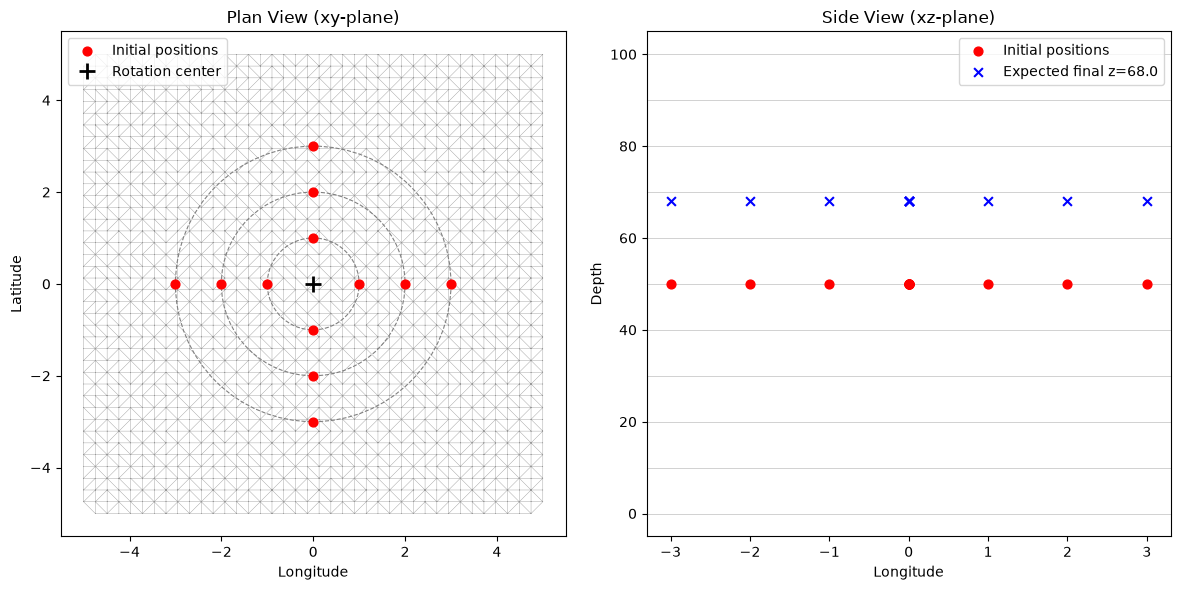

In [4]:
# Visualize grid and initial particle positions (plan view)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

triang = mtri.Triangulation(
    uxgrid.node_lon.values, uxgrid.node_lat.values,
    triangles=uxgrid.face_node_connectivity.values,
)

# Plan view
ax = axes[0]
ax.triplot(triang, "k-", lw=0.3, alpha=0.4)
for R in RADII:
    circle = plt.Circle((0, 0), R, fill=False, ls="--", color="gray", lw=0.8)
    ax.add_patch(circle)
ax.scatter(p_lon0, p_lat0, c="red", s=40, zorder=5, label="Initial positions")
ax.plot(0, 0, "k+", ms=12, mew=2, label="Rotation center")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Plan View (xy-plane)")
ax.legend()
ax.set_aspect("equal")

# Side view showing vertical layers
ax = axes[1]
for z in zf:
    ax.axhline(z, color="gray", lw=0.5, alpha=0.5)
ax.scatter(p_lon0, p_depth0, c="red", s=40, zorder=5, label="Initial positions")
z_final = Z0 + W0 * T_TOTAL_S
ax.scatter(p_lon0, np.full_like(p_lon0, z_final), c="blue", s=40, zorder=5,
           marker="x", label=f"Expected final z={z_final:.1f}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Depth")
ax.set_title("Side View (xz-plane)")
ax.legend()

plt.tight_layout()
plt.show()

## 3. Define Velocity Fields

Solid-body rotation about the origin with constant vertical velocity:
$$u = -\Omega\,y, \quad v = \Omega\,x, \quad w = W_0$$

The horizontal field is linear, so barycentric (node-centered) interpolation reproduces it
exactly. The vertical velocity is constant, so both face- and node-centered interpolation
are exact.

The velocity field is defined on multiple vertical layers to exercise 3D interpolation stencils.

In [5]:
def make_face_centered_dataset(uxgrid, omega, w0):
    """Velocity on face centers (U, V) and nodes (W) with multiple vertical layers."""
    face_lon = uxgrid.face_lon.values
    face_lat = uxgrid.face_lat.values

    u_vals = -omega * face_lat  # (n_face,)
    v_vals = omega * face_lon

    # Broadcast to (time, zc, n_face) — same velocity at every layer
    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    W = np.full((N_TIMESTEPS, zf.size, uxgrid.n_node), w0, dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (solid-body rotation)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (solid-body rotation)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity (constant)"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def make_node_centered_dataset(uxgrid, omega, w0):
    """Velocity on corner nodes (U, V, W) with multiple vertical layers."""
    node_lon = uxgrid.node_lon.values
    node_lat = uxgrid.node_lat.values

    u_vals = -omega * node_lat
    v_vals = omega * node_lon

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    W = np.full((N_TIMESTEPS, zf.size, uxgrid.n_node), w0, dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (solid-body rotation)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (solid-body rotation)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity (constant)"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


ds_face = make_face_centered_dataset(uxgrid, OMEGA, W0)
ds_node = make_node_centered_dataset(uxgrid, OMEGA, W0)

print("Face-centered dataset:")
print(ds_face)
print()
print("Node-centered dataset:")
print(ds_node)

Face-centered dataset:
<xarray.UxDataset> Size: 627kB
Dimensions:  (time: 1, zc: 10, n_face: 3039, zf: 11, n_node: 1600)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 80B 5.0 15.0 25.0 35.0 45.0 55.0 65.0 75.0 85.0 95.0
  * zf       (zf) float64 88B 0.0 10.0 20.0 30.0 40.0 ... 70.0 80.0 90.0 100.0
Dimensions without coordinates: n_face, n_node
Data variables:
    U        (time, zc, n_face) float64 243kB 0.0008205 0.0009696 ... 0.004848
    V        (time, zc, n_face) float64 243kB -0.008577 -0.008428 ... 0.002611
    W        (time, zf, n_node) float64 141kB 0.005 0.005 0.005 ... 0.005 0.005

Node-centered dataset:
<xarray.UxDataset> Size: 397kB
Dimensions:  (time: 1, zc: 10, n_node: 1600, zf: 11)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 80B 5.0 15.0 25.0 35.0 45.0 55.0 65.0 75.0 85.0 95.0
  * zf       (zf) float64 88B 0.0 10.0 20.0 30.0 40.0 ... 70.0 80.0 90.0 100.0
Dimensions without coordinates

## 4. Analytical Solution

For the 3D helical field $\mathbf{u} = (-\Omega y,\; \Omega x,\; W_0)$, a particle starting
at $(x_0, y_0, z_0)$ follows:

$$x(t) = R\cos(\Omega t + \varphi_0), \quad y(t) = R\sin(\Omega t + \varphi_0), \quad z(t) = z_0 + W_0 t$$

where $R = \sqrt{x_0^2 + y_0^2}$ and $\varphi_0 = \mathrm{atan2}(y_0, x_0)$.

Key invariants:
- **Radius** is conserved: $\sqrt{x(t)^2 + y(t)^2} = R$ for all $t$
- **Vertical velocity** is constant: $\dot{z} = W_0$
- **Angular velocity** is constant: $\dot{\varphi} = \Omega$

In [6]:
def analytical_position_3d(lon0, lat0, depth0, omega, w0, dt_seconds):
    """Exact particle position after dt_seconds of helical motion."""
    R = np.sqrt(lon0**2 + lat0**2)
    phi0 = np.arctan2(lat0, lon0)
    phi = phi0 + omega * dt_seconds
    return R * np.cos(phi), R * np.sin(phi), depth0 + w0 * dt_seconds


def analytical_trajectory_3d(lon0, lat0, depth0, omega, w0, t_array):
    """Exact trajectory at an array of times (seconds)."""
    R = np.sqrt(lon0**2 + lat0**2)
    phi0 = np.arctan2(lat0, lon0)
    phi = phi0 + omega * t_array
    return R * np.cos(phi), R * np.sin(phi), depth0 + w0 * t_array

## 5. Run Advection: All Interpolator / Time Integrator Combinations

| Data Location | Interpolator | Description |
|---|---|---|
| Face-centered | `UxConstantFaceConstantZC` | Piecewise constant (face), constant vertical |
| Node-centered | `UxLinearNodeConstantZC` | Barycentric linear (node), constant vertical |

Time integrators:
- **Euler** (`AdvectionEE`) — order 1
- **Runge-Kutta 4** (`AdvectionRK4`) — order 4

We use the baseline $\Delta t$ for this initial comparison.

In [7]:
time_integrators = {
    "EE": parcels.kernels.AdvectionEE,
    "RK4": parcels.kernels.AdvectionRK4,
}

field_configs = {
    "face-centered": ds_face,
    "node-centered": ds_node,
}

# Older Parcels versions left pset.x/lat at T - dt after execute() with an output file
# (see issues/one-step-lag-in-particle-output.md); current main ends at T exactly.
DT_BASE_S = DT_BASE / np.timedelta64(1, 's')

results = []
output_files = {}

for field_label, ds in field_configs.items():
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds, mesh="flat")

    for integrator_label, integrator in time_integrators.items():
        out_name = f"T1_3_{field_label}_{integrator_label}.parquet"

        pset = parcels.ParticleSet(
            fieldset,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
            z=p_depth0.copy(),
        )

        pfile = parcels.ParticleFile(path=out_name, outputdt=DT_BASE, mode="w")

        pset.execute(
            integrator,
            runtime=T_TOTAL,
            dt=DT_BASE,
            output_file=pfile,
            verbose_progress=False,
        )

        lon_exact, lat_exact, depth_exact = analytical_position_3d(
            p_lon0, p_lat0, p_depth0, OMEGA, W0, T_TOTAL_S)
        lon_err = pset.x - lon_exact
        lat_err = pset.y - lat_exact
        depth_err = pset.z - depth_exact
        horiz_err = np.sqrt(lon_err**2 + lat_err**2)
        total_err = np.sqrt(lon_err**2 + lat_err**2 + depth_err**2)

        # Radius drift (angular momentum conservation)
        R_exact = np.sqrt(p_lon0**2 + p_lat0**2)
        R_final = np.sqrt(pset.x**2 + pset.y**2)
        radius_err = np.abs(R_final - R_exact)

        key = f"{field_label} / {integrator_label}"
        output_files[key] = out_name

        results.append({
            "field_location": field_label,
            "integrator": integrator_label,
            "output": out_name,
            "max_horiz_error": np.max(horiz_err),
            "max_depth_error": np.max(np.abs(depth_err)),
            "max_total_error": np.max(total_err),
            "max_radius_error": np.max(radius_err),
        })

        print(f"{field_label:16s} | {integrator_label:4s} | "
              f"max |horiz err| = {np.max(horiz_err):.4e}  "
              f"max |depth err| = {np.max(np.abs(depth_err)):.4e}  "
              f"max |R err| = {np.max(radius_err):.4e}")

INFO: Output files are stored in T1_3_face-centered_EE.parquet
face-centered    | EE   | max |horiz err| = 5.7732e-01  max |depth err| = 1.8000e+01  max |R err| = 5.7731e-01
INFO: Output files are stored in T1_3_face-centered_RK4.parquet
face-centered    | RK4  | max |horiz err| = 1.4279e-01  max |depth err| = 1.8000e+01  max |R err| = 2.1799e-02
INFO: Output files are stored in T1_3_node-centered_EE.parquet
node-centered    | EE   | max |horiz err| = 5.3592e-01  max |depth err| = 1.8000e+01  max |R err| = 5.3559e-01
INFO: Output files are stored in T1_3_node-centered_RK4.parquet
node-centered    | RK4  | max |horiz err| = 1.1748e-06  max |depth err| = 1.8000e+01  max |R err| = 5.6381e-08


## 6. Results Summary

In [8]:
df = pd.DataFrame(results)
df

,field_location,integrator,output,max_horiz_error,max_depth_error,max_total_error,max_radius_error
0,face-centered,EE,T1_3_face-centered_EE.parquet,0.577322,18.0,18.009256,5.773071e-01
1,face-centered,RK4,T1_3_face-centered_RK4.parquet,0.142790,18.0,18.000566,2.179883e-02
2,node-centered,EE,T1_3_node-centered_EE.parquet,0.535917,18.0,18.007976,5.355915e-01
3,node-centered,RK4,T1_3_node-centered_RK4.parquet,0.000001,18.0,18.000000,5.638095e-08


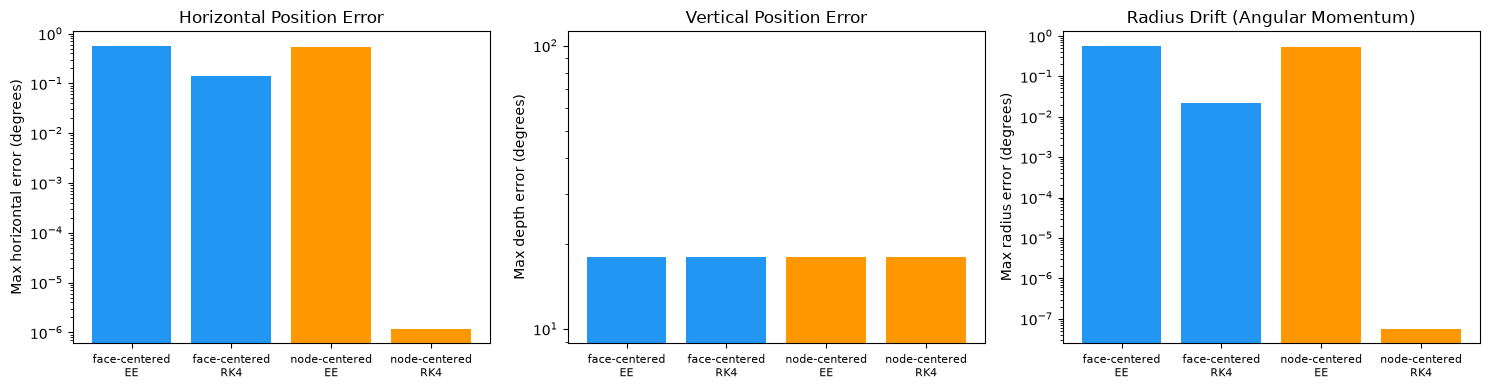

: 

In [ ]:
# Error bar charts
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

labels = [f"{r['field_location']}\n{r['integrator']}" for r in results]
colors = ["#2196F3" if "face" in r["field_location"] else "#FF9800" for r in results]

# Horizontal error
ax = axes[0]
ax.bar(range(len(results)), [r["max_horiz_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max horizontal error (degrees)")
ax.set_title("Horizontal Position Error")
ax.set_yscale("log")

# Depth error
ax = axes[1]
ax.bar(range(len(results)), [r["max_depth_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max depth error (degrees)")
ax.set_title("Vertical Position Error")
ax.set_yscale("log")

# Radius error
ax = axes[2]
ax.bar(range(len(results)), [r["max_radius_error"] for r in results], color=colors)
ax.set_xticks(range(len(results)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Max radius error (degrees)")
ax.set_title("Radius Drift (Angular Momentum)")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## 7. Trajectory Visualization

Overlay computed trajectories against the analytical helices. Show both plan view (xy) and
side view (xz) for each combination.

In [ ]:
n_combos = len(output_files)
fig, axes = plt.subplots(n_combos, 2, figsize=(14, 7 * n_combos), squeeze=False)

t_fine = np.linspace(0, T_TOTAL_S, 500)

for idx, (label, out_path) in enumerate(output_files.items()):
    ax_plan = axes[idx, 0]
    ax_side = axes[idx, 1]

    # Grid (plan view only)
    ax_plan.triplot(triang, "k-", lw=0.2, alpha=0.2)

    # Analytical trajectories
    for i in range(N_PARTICLES):
        xa, ya, za = analytical_trajectory_3d(
            p_lon0[i], p_lat0[i], p_depth0[i], OMEGA, W0, t_fine)
        ax_plan.plot(xa, ya, "r-", lw=0.6, alpha=0.4,
                     label="Analytical" if i == 0 else None)
        ax_side.plot(xa, za, "r-", lw=0.6, alpha=0.4,
                     label="Analytical" if i == 0 else None)

    # Computed trajectories from the parquet particle file
    traj_df = parcels.read_particlefile(out_path).sort("particle_id", "t")
    for p, pid in enumerate(traj_df["particle_id"].unique().sort()):
        traj = traj_df.filter(traj_df["particle_id"] == pid)
        lons = traj["x"].to_numpy()
        lats = traj["y"].to_numpy()
        depths = traj["z"].to_numpy()
        ax_plan.plot(lons, lats, "b.-", ms=1.5, lw=0.5,
                     label="Computed" if p == 0 else None)
        ax_side.plot(lons, depths, "b.-", ms=1.5, lw=0.5,
                     label="Computed" if p == 0 else None)

    ax_plan.scatter(p_lon0, p_lat0, c="green", s=30, zorder=5, label="Start")
    ax_plan.plot(0, 0, "k+", ms=10, mew=2)
    ax_plan.set_xlabel("Longitude")
    ax_plan.set_ylabel("Latitude")
    ax_plan.set_title(f"{label} — Plan View (xy)")
    ax_plan.legend(fontsize=7, loc="upper right")
    ax_plan.set_aspect("equal")

    ax_side.scatter(p_lon0, p_depth0, c="green", s=30, zorder=5, label="Start")
    ax_side.set_xlabel("Longitude")
    ax_side.set_ylabel("Depth")
    ax_side.set_title(f"{label} — Side View (xz)")
    ax_side.legend(fontsize=7, loc="upper right")

fig.suptitle(f"T1-3: 3D Helix — Computed vs Analytical ({N_ORBITS} orbits)",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8. Convergence Study ($\Delta t$ refinement, node-centered)

On the node-centered grid the interpolant is exact for the linear horizontal field and
constant vertical field, so all error comes from the time integrator.

We measure convergence in both horizontal position error and depth error separately.

In [ ]:
DT_VALUES = [300, 150, 60, 30, 15]

T_CONV_S = PERIOD
T_CONV = np.timedelta64(int(T_CONV_S), "s")

convergence_results = []

fieldset_node = parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")

for integrator_label, integrator in time_integrators.items():
    for dt_s in DT_VALUES:
        dt = np.timedelta64(dt_s, "s")

        pset = parcels.ParticleSet(
            fieldset_node,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
            z=p_depth0.copy(),
        )

        pset.execute(
            integrator,
            runtime=T_CONV,
            dt=dt,
            verbose_progress=False,
        )

        # No lag correction needed: pset.x
        # is at T exactly (when T is divisible by dt).
        lon_exact, lat_exact, depth_exact = analytical_position_3d(
            p_lon0, p_lat0, p_depth0, OMEGA, W0, T_CONV_S)
        horiz_err = np.sqrt((pset.x - lon_exact)**2 + (pset.y - lat_exact)**2)
        depth_err = np.abs(pset.z - depth_exact)

        convergence_results.append({
            "integrator": integrator_label,
            "dt_s": dt_s,
            "max_horiz_error": np.max(horiz_err),
            "max_depth_error": np.max(depth_err),
        })

        print(f"{integrator_label:4s} | dt={dt_s:4d}s | "
              f"max horiz err = {np.max(horiz_err):.4e}  "
              f"max depth err = {np.max(depth_err):.4e}")

df_conv = pd.DataFrame(convergence_results)
df_conv

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

markers = {"EE": "o", "RK4": "s"}
colors_int = {"EE": "#E53935", "RK4": "#1E88E5"}
expected_orders = {"EE": 1, "RK4": 4}

for err_col, ax, title in [
    ("max_horiz_error", axes[0], "Horizontal Position Error"),
    ("max_depth_error", axes[1], "Depth Error"),
]:
    for integrator_label in time_integrators:
        mask = df_conv["integrator"] == integrator_label
        dts = df_conv.loc[mask, "dt_s"].values.astype(float)
        errs = df_conv.loc[mask, err_col].values

        ax.loglog(dts, errs, f"{markers[integrator_label]}-",
                  color=colors_int[integrator_label],
                  label=f"{integrator_label} (measured)", ms=8, lw=2)

        if len(dts) >= 2 and np.all(errs > 0):
            slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
            p = expected_orders[integrator_label]
            ref_err = errs[-1] * (dts / dts[-1])**p
            ax.loglog(dts, ref_err, "--",
                      color=colors_int[integrator_label], alpha=0.5,
                      label=f"{integrator_label} ref slope={p} (measured={slope:.2f})")

    ax.set_xlabel(r"$\Delta t$ (seconds)")
    ax.set_ylabel("Max error (degrees)")
    ax.set_title(f"T1-3 Convergence: {title}")
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Verification Assertions

### Node-centered checks
With exact interpolation of the linear horizontal field and constant vertical field:
1. **Convergence order:** measured slope should be within 0.5 of the expected order
2. **RK4 at fine dt:** horizontal error should be very small (< 1e-6 after 1 orbit)
3. **Depth error:** for constant $w$, depth should be exact to machine precision for all integrators

### Face-centered checks
Piecewise-constant interpolation introduces horizontal spatial error, so we only check that
the simulation completes and particles stay within a reasonable bound.

In [ ]:
all_pass = True

# --- Check 1: Convergence orders (node-centered, horizontal) ---
print("=== Convergence Order Checks (node-centered, horizontal) ===")
for integrator_label in time_integrators:
    mask = df_conv["integrator"] == integrator_label
    dts = df_conv.loc[mask, "dt_s"].values.astype(float)
    errs = df_conv.loc[mask, "max_horiz_error"].values

    if len(dts) >= 2 and np.all(errs > 0):
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
        expected = expected_orders[integrator_label]
        ok = abs(slope - expected) < 0.5
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {integrator_label}: measured slope = {slope:.2f}, "
              f"expected ~ {expected}")
    else:
        print(f"  [SKIP] {integrator_label}: insufficient data for slope")

# --- Check 2: RK4 absolute accuracy at finest dt ---
print("\n=== RK4 Absolute Accuracy (node-centered, finest dt) ===")
rk4_finest = df_conv.loc[
    (df_conv["integrator"] == "RK4") & (df_conv["dt_s"] == min(DT_VALUES)),
    "max_horiz_error"
].values
if len(rk4_finest) > 0:
    err = rk4_finest[0]
    ok = err < 1e-6
    status = "PASS" if ok else "FAIL"
    if not ok:
        all_pass = False
    print(f"  [{status}] RK4 max horiz error at dt={min(DT_VALUES)}s: {err:.4e} (threshold 1e-6)")

# --- Check 3: Depth error should be near machine precision ---
print("\n=== Depth Error Checks (node-centered) ===")
DEPTH_TOL = 1e-8
for _, row in df_conv.iterrows():
    ok = row["max_depth_error"] < DEPTH_TOL
    status = "PASS" if ok else "FAIL"
    if not ok:
        all_pass = False
    print(f"  [{status}] {row['integrator']} dt={row['dt_s']}s: "
          f"max depth err = {row['max_depth_error']:.4e} (threshold {DEPTH_TOL:.0e})")

# --- Check 4: Face-centered runs complete with bounded error ---
print("\n=== Face-Centered Sanity Checks ===")
for r in results:
    if r["field_location"] == "face-centered":
        ok = r["max_total_error"] < 5.0
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  [{status}] {r['field_location']} / {r['integrator']}: "
              f"max err = {r['max_total_error']:.4e}")

print()
if all_pass:
    print("T1-3 PASSED: All checks within tolerance.")
else:
    raise AssertionError(
        "T1-3 FAILED: One or more checks exceeded tolerance. "
        "Review convergence plots above."
    )

## 10. Cleanup

In [ ]:
for out_path in output_files.values():
    if os.path.exists(out_path):
        os.remove(out_path)
print("Temporary output cleaned up.")